# Codebook con K-Means (1k)

Probar varios K para SIFT (portadas) y MFCC (audio) con el dataset de 1 000 canciones y ver cuál recupera mejor

In [1]:
import os, sys, time
REPO = os.path.abspath("..")
sys.path.insert(0, REPO)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score

from multimedia.codebook import (objetos, cargar_todo, muestra, consultas_sift,
                                 consultas_mfcc, tfidf, asignar)

DATA = os.path.join(REPO, "data", "sim_1k")
CACHE = os.path.join(DATA, "features", "codebook")
KS = [64, 128, 256, 512, 1024, 2048, 4096]
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "font.size": 10})

## 1. Descriptores

Se juntan todos los descriptores de la base, se estandariza el MFCC y se saca una muestra de máximo 50 por objeto para entrenar

In [2]:
def preparar(tipo):
    rng = np.random.default_rng(0)
    objs = objetos(tipo, DATA)
    X, dueno = cargar_todo(objs, DATA)
    n_desc = np.bincount(dueno, minlength=len(objs))
    media, desv = np.zeros(X.shape[1], np.float32), np.ones(X.shape[1], np.float32)
    if tipo == "mfcc":
        media, desv = X.mean(0), X.std(0) + 1e-6
        X = (X - media) / desv
    S = muestra(X, dueno, rng)

    cache = os.path.join(CACHE, f"consultas_{tipo}.npz")
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        consultas = list(zip(z["nombre"], z["objetivo"], z["desc"]))
    else:
        consultas = (consultas_sift if tipo == "sift" else consultas_mfcc)(objs, n_desc, rng, DATA)
    consultas = [(n, int(o), (np.asarray(d, np.float32) - media) / desv) for n, o, d in consultas]
    return {"objs": objs, "X": X, "dueno": dueno, "S": S, "consultas": consultas}

datos = {t: preparar(t) for t in ("sift", "mfcc")}
for t, d in datos.items():
    print(f"{t}: {len(d['objs'])} objetos, {len(d['X'])} descriptores de {d['X'].shape[1]} dims, "
          f"muestra {len(d['S'])}, {len(d['consultas'])} consultas")

sift: 877 objetos, 398869 descriptores de 128 dims, muestra 43682, 1200 consultas
mfcc: 1003 objetos, 1293049 descriptores de 39 dims, muestra 50136, 600 consultas


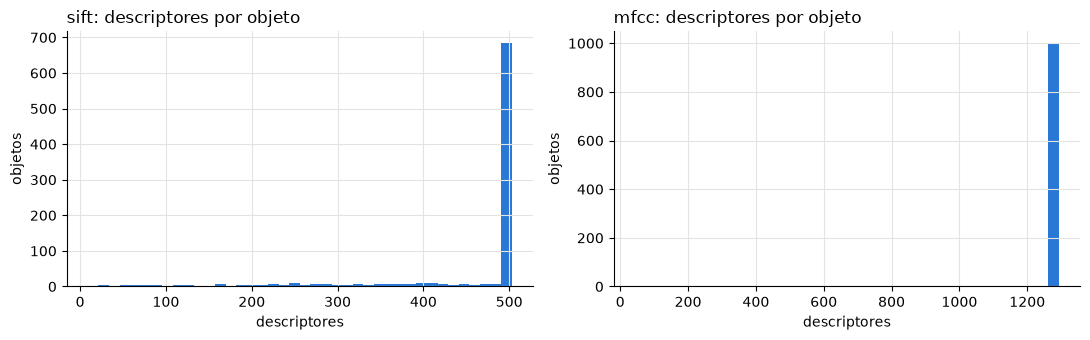

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (t, d) in zip(axs, datos.items()):
    ax.hist(np.bincount(d["dueno"]), bins=40, color=SERIES[0])
    ax.set_title(f"{t}: descriptores por objeto", loc="left")
    ax.set_xlabel("descriptores")
    ax.set_ylabel("objetos")
plt.tight_layout()

## 2. K-Means para un K

MiniBatchKMeans con k-means++, 3 inicializaciones y semilla fija. Primero un solo K para ver qué sale

centroides (256, 128) en 3.3 s


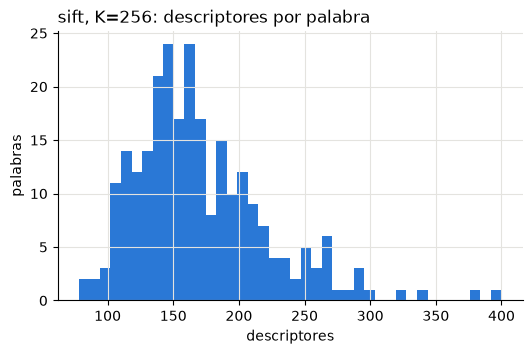

In [4]:
def entrenar(S, K):
    t0 = time.time()
    km = MiniBatchKMeans(n_clusters=K, init="k-means++", batch_size=4096,
                         init_size=max(3 * 4096, 3 * K), n_init=3, max_iter=100,
                         random_state=0).fit(S)
    return km, time.time() - t0

km, seg = entrenar(datos["sift"]["S"], 256)
etiq = km.predict(datos["sift"]["S"])
print(f"centroides {km.cluster_centers_.shape} en {seg:.1f} s")

plt.figure(figsize=(6, 3.5))
plt.hist(np.bincount(etiq, minlength=256), bins=40, color=SERIES[0])
plt.title("sift, K=256: descriptores por palabra", loc="left")
plt.xlabel("descriptores")
plt.ylabel("palabras");

## 3. Evaluar

Cada descriptor de la base se asigna a su palabra, cada objeto queda como histograma TF-IDF y cada consulta busca por coseno. recall@10 es si la respuesta correcta sale entre las 10 primeras

In [5]:
def evaluar(d, K):
    km, seg = entrenar(d["S"], K)
    etiq_s = km.predict(d["S"])
    tam = np.bincount(etiq_s, minlength=K)
    sub = np.random.default_rng(0).choice(len(d["S"]), min(20_000, len(d["S"])), replace=False)
    fila = {"K": K,
            "inercia": ((d["S"] - km.cluster_centers_[etiq_s]) ** 2).sum(1).mean(),
            "davies_bouldin": davies_bouldin_score(d["S"][sub], etiq_s[sub]),
            "silhouette": silhouette_score(d["S"][sub[:10_000]], etiq_s[sub[:10_000]]),
            "palabras_vacias": int((tam < 5).sum()),
            "mediana_por_palabra": int(np.median(tam)),
            "entrenar_s": seg}

    t0 = time.time()
    base, idf = tfidf(asignar(km, d["X"]), d["dueno"], len(d["objs"]), K)
    fila["construir_s"] = time.time() - t0

    puestos = {}
    t0 = time.time()
    for nombre, objetivo, q in d["consultas"]:
        if len(q) == 0:
            puestos.setdefault(nombre, []).append(10 ** 9)
            continue
        v, _ = tfidf(km.predict(q), np.zeros(len(q), int), 1, K, idf)
        sim = base @ v[0]
        puestos.setdefault(nombre, []).append(int((sim > sim[objetivo]).sum()) + 1)
    fila["consulta_ms"] = (time.time() - t0) / len(d["consultas"]) * 1000
    for nombre, p in puestos.items():
        fila[f"r10 {nombre}"] = np.mean(np.array(p) <= 10)
    return fila, tam

fila, _ = evaluar(datos["sift"], 256)
pd.Series(fila).round(3)

K                      256.000
inercia                  0.196
davies_bouldin           2.826
silhouette               0.035
palabras_vacias          0.000
mediana_por_palabra    161.000
entrenar_s               3.034
construir_s              0.125
consulta_ms              0.458
r10 rotar 15°            1.000
r10 recortar 70 %        0.820
r10 oscurecer 60 %       0.993
r10 jpeg + 200 px        0.450
dtype: float64

## 4. Barrido de K

In [6]:
resultados, tamanos = {}, {}
for t, d in datos.items():
    filas = []
    for K in KS:
        fila, tam = evaluar(d, K)
        filas.append(fila)
        tamanos[(t, K)] = tam
        print(f"{t} K={K}: {fila['entrenar_s']:.0f} s")
    resultados[t] = pd.DataFrame(filas).set_index("K")

sift K=64: 1 s


sift K=128: 2 s


sift K=256: 3 s


sift K=512: 6 s


sift K=1024: 12 s


sift K=2048: 23 s


... (4 outputs left out)

mfcc K=512: 2 s


mfcc K=1024: 3 s


mfcc K=2048: 7 s


mfcc K=4096: 15 s


In [7]:
resultados["sift"].round(3)

,inercia,davies_bouldin,silhouette,palabras_vacias,mediana_por_palabra,entrenar_s,construir_s,consulta_ms,r10 rotar 15°,r10 recortar 70 %,r10 oscurecer 60 %,r10 jpeg + 200 px
K,,,,,,,,,,,,
64,0.233,2.955,0.043,0,669,0.797,0.033,0.184,0.990,0.673,0.980,0.227
128,0.214,2.920,0.042,0,341,1.543,0.067,0.282,1.000,0.760,0.993,0.300
256,0.196,2.826,0.035,0,161,3.117,0.100,0.418,1.000,0.820,0.993,0.450
512,0.180,2.715,0.030,1,83,6.007,0.224,0.672,0.997,0.870,0.993,0.523
1024,0.164,2.470,0.012,34,41,12.474,0.362,1.334,1.000,0.930,1.000,0.673
2048,0.149,2.117,-0.017,335,19,22.770,0.688,2.490,1.000,0.963,1.000,0.780
4096,0.130,1.782,-0.036,1539,8,54.525,1.405,4.903,1.000,0.987,1.000,0.807


In [8]:
resultados["mfcc"].round(3)

,inercia,davies_bouldin,silhouette,palabras_vacias,mediana_por_palabra,entrenar_s,construir_s,consulta_ms,r10 fragmento 5 s,r10 5 s + volumen y ruido
K,,,,,,,,,,
64,29.177000,3.480,-0.035,0,775,0.242,0.093,0.125,0.610,0.383
128,27.708000,3.383,-0.036,0,367,0.457,0.119,0.147,0.750,0.523
256,26.146999,3.165,-0.042,0,185,0.928,0.202,0.222,0.877,0.610
512,24.629000,2.915,-0.042,0,88,1.828,0.327,0.409,0.927,0.687
1024,23.101999,2.557,-0.055,32,40,3.256,0.705,0.690,0.970,0.750
2048,20.955999,2.157,-0.072,257,16,7.495,1.255,1.383,0.983,0.773
4096,18.544001,1.782,-0.094,1413,7,15.077,2.501,2.679,0.990,0.817


## 5. Gráficas

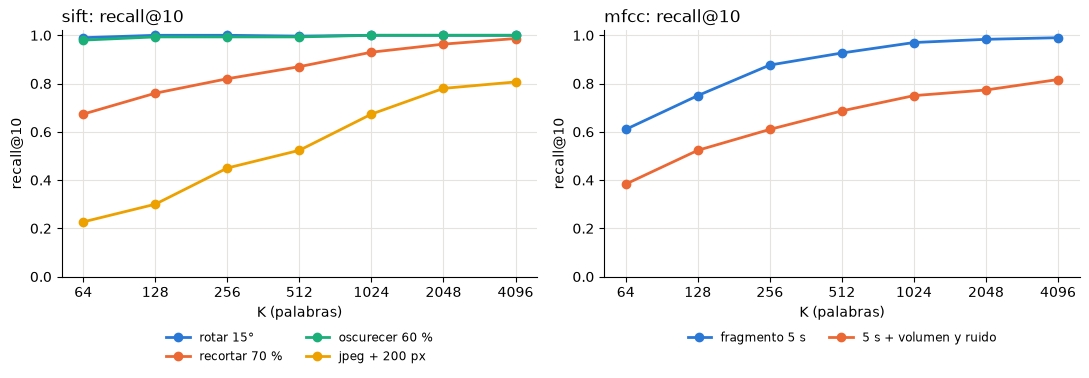

In [9]:
def por_k(columnas, titulo, ylabel, ylim=None):
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    for ax, (t, df) in zip(axs, resultados.items()):
        cols = [c for c in df.columns if columnas(c)]
        for i, col in enumerate(cols):
            ax.plot(df.index, df[col], marker="o", linewidth=2, color=SERIES[i],
                    label=col.replace("r10 ", ""))
        ax.set_xscale("log", base=2)
        ax.set_xticks(KS, [str(k) for k in KS])
        ax.minorticks_off()
        ax.set_title(f"{t}: {titulo}", loc="left")
        ax.set_xlabel("K (palabras)")
        ax.set_ylabel(ylabel)
        if ylim:
            ax.set_ylim(*ylim)
        if len(cols) > 1:
            ax.legend(frameon=False, fontsize=8.5, loc="upper center", ncol=2,
                      bbox_to_anchor=(0.5, -0.18))
    plt.tight_layout()

por_k(lambda c: c.startswith("r10"), "recall@10", "recall@10", (0, 1.02))

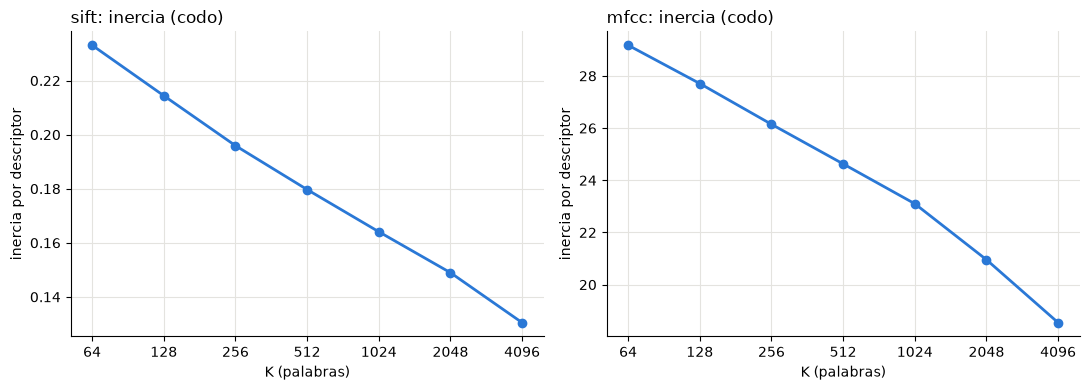

In [10]:
por_k(lambda c: c == "inercia", "inercia (codo)", "inercia por descriptor")

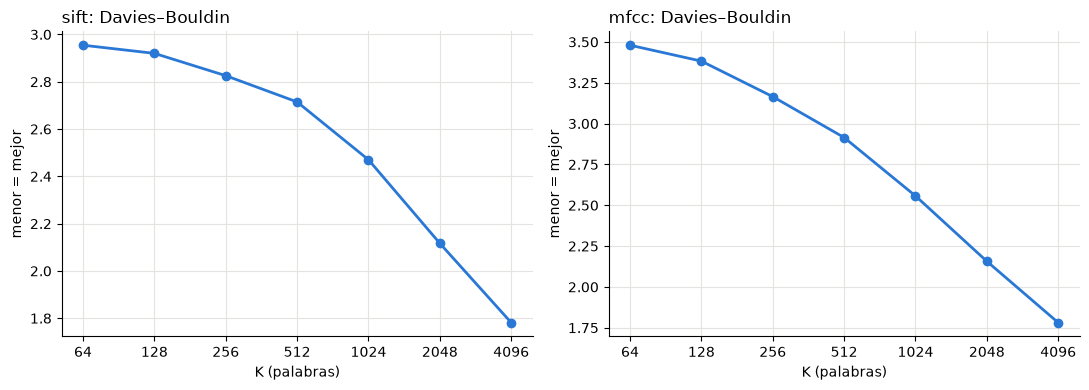

In [11]:
por_k(lambda c: c == "davies_bouldin", "Davies–Bouldin", "menor = mejor")

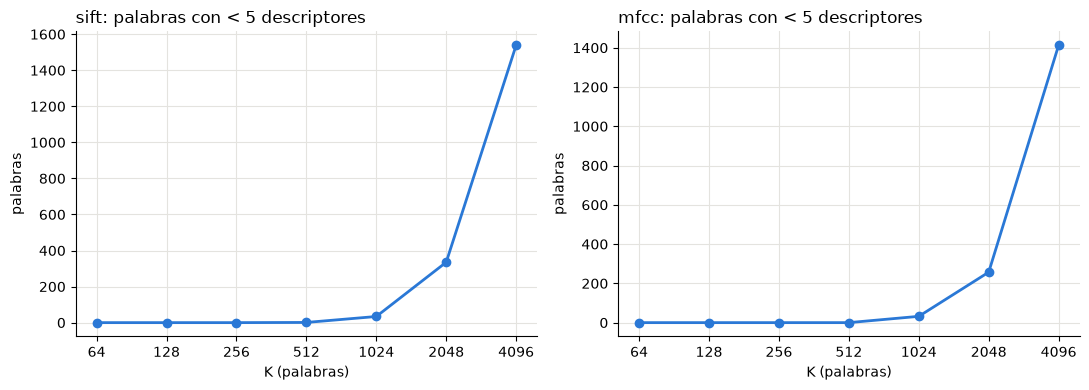

In [12]:
por_k(lambda c: c == "palabras_vacias", "palabras con < 5 descriptores", "palabras")

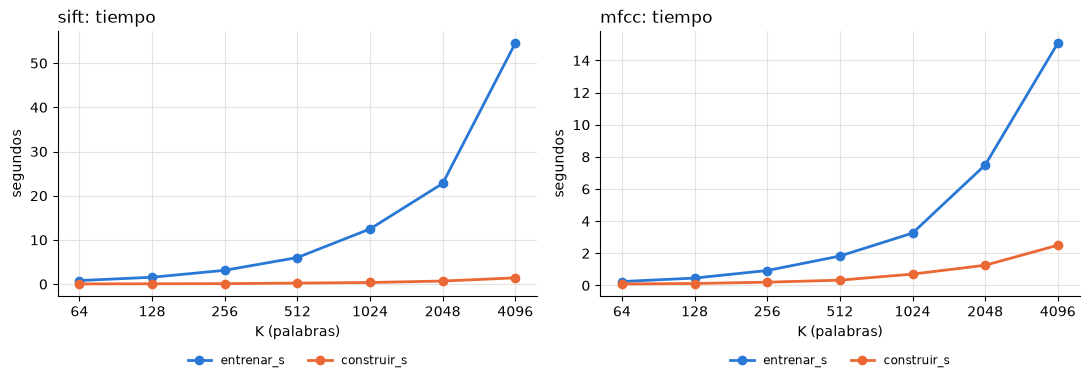

In [13]:
por_k(lambda c: c in ("entrenar_s", "construir_s"), "tiempo", "segundos")

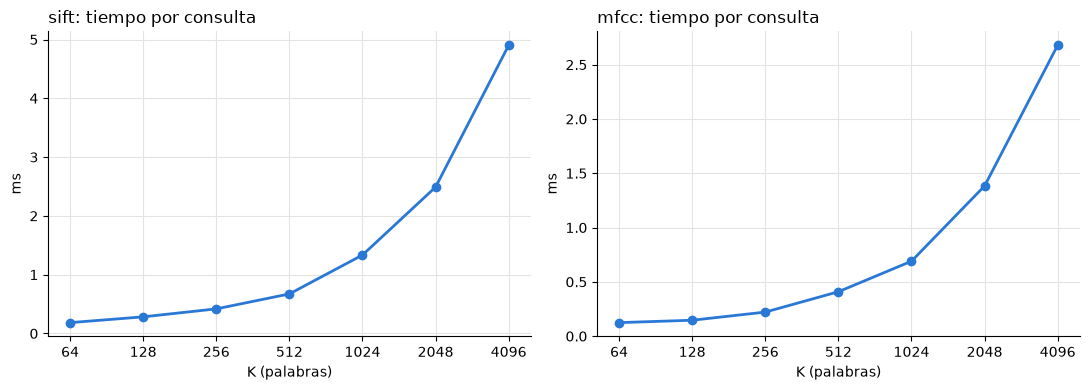

In [14]:
por_k(lambda c: c == "consulta_ms", "tiempo por consulta", "ms")

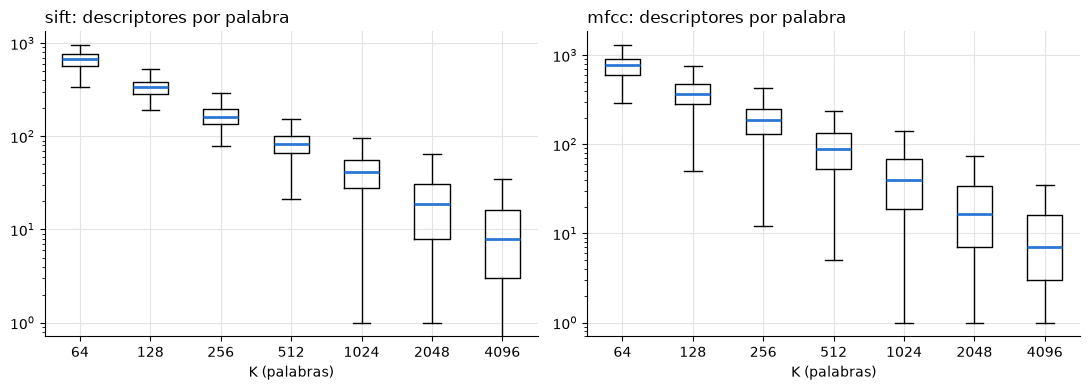

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, t in zip(axs, resultados):
    ax.boxplot([tamanos[(t, K)] for K in KS], tick_labels=[str(k) for k in KS], showfliers=False,
               medianprops={"color": SERIES[0], "linewidth": 2})
    ax.set_yscale("log")
    ax.set_title(f"{t}: descriptores por palabra", loc="left")
    ax.set_xlabel("K (palabras)")
plt.tight_layout()

## 6. Qué K elegir

Para ambos casos (tanto imágenes como audio) elegimos K=1024 ya que es altamente prioritario mantener un recall@10 lo suficientemente alto sin sacrificar demasiado los tiempos de consulta, entrenamiento y construcción. Si se quisiera sacrificar eficiencia para que las operaciones demoren la mitad del tiempo, se podría usar K=512 para ambos formatos, lo que no causaría mucha diferencia en imágenes o audios con características "normales" aunque podría tener un efecto significativo en aquellos recortados u obfuscados de alguna forma. No sería viable un K mayor ya que el tiempo por consulta y la cantidad de palabras con menos de 5 descriptores escalarían demasiado. A pesar de que con K=1024 sí existen palabras con muy pocos descriptores, estos casos son raros, mientras que son más frecuentes para K=2048 en adelante.